In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv('../W5D3/indian_business_dataset.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,business_id,business_name,owner_name,state,city,age,email,phone,annual_revenue,gstin
0,B001,Sri Traders,Ravi Kumar,Andhra Pradesh,Tirupati,35,owner1@example.com,9000000001,500000,37ABCDE0001F1Z5
1,B002,ABC Stores,Anita Rao,Telangana,Hyderabad,42,owner2@example.com,9000000002,750000,37ABCDE0002F1Z5
2,B003,Lakshmi Textiles,Lakshmi Devi,Karnataka,Bengaluru,29,owner3@example.com,9000000003,420000,37ABCDE0003F1Z5
3,B004,Green Mart,Suresh Reddy,Tamil Nadu,Chennai,51,owner4@example.com,9000000004,900000,37ABCDE0004F1Z5
4,B005,Ravi Enterprises,Priya Sharma,Maharashtra,Pune,38,NaN,9000000005,650000,37ABCDE0005F1Z5


In [4]:
print("Dataset Shape:", df.shape)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Dataset Shape: (50, 10)
Total Rows: 50
Total Columns: 10


In [5]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['business_id', 'business_name', 'owner_name', 'state', 'city', 'age', 'email', 'phone', 'annual_revenue', 'gstin']


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   business_id     50 non-null     str  
 1   business_name   50 non-null     str  
 2   owner_name      50 non-null     str  
 3   state           50 non-null     str  
 4   city            50 non-null     str  
 5   age             50 non-null     int64
 6   email           49 non-null     str  
 7   phone           50 non-null     int64
 8   annual_revenue  50 non-null     int64
 9   gstin           50 non-null     str  
dtypes: int64(3), str(7)
memory usage: 4.0 KB


In [7]:
df.describe()

,age,phone,annual_revenue
count,50.000000,5.000000e+01,50.000000
mean,40.820000,9.000000e+09,629000.000000
std,17.305998,1.457738e+01,162722.375316
min,27.000000,9.000000e+09,380000.000000
25%,33.000000,9.000000e+09,500000.000000
50%,39.000000,9.000000e+09,625000.000000
75%,44.000000,9.000000e+09,750000.000000
max,150.000000,9.000000e+09,900000.000000


In [8]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

Missing Values:
business_id       0
business_name     0
owner_name        0
state             0
city              0
age               0
email             1
phone             0
annual_revenue    0
gstin             0
dtype: int64


In [9]:
duplicates = df.duplicated().sum()

print("Total Duplicate Rows:", duplicates)

Total Duplicate Rows: 0


In [10]:
df[df['email'].isnull()]

,business_id,business_name,owner_name,state,city,age,email,phone,annual_revenue,gstin
4,B005,Ravi Enterprises,Priya Sharma,Maharashtra,Pune,38,NaN,9000000005,650000,37ABCDE0005F1Z5


In [11]:
df['email'] = df['email'].fillna('Not Available')

print("Missing email values after cleaning:")
print(df['email'].isnull().sum())

Missing email values after cleaning:
0


In [12]:
df = df.drop_duplicates()

print("Duplicate records after cleaning:", df.duplicated().sum())

Duplicate records after cleaning: 0


In [13]:
total_revenue = df['annual_revenue'].sum()

print("Total Business Revenue:", total_revenue)

Total Business Revenue: 31450000


In [14]:
average_revenue = df['annual_revenue'].mean()

print("Average Business Revenue:", average_revenue)

Average Business Revenue: 629000.0


In [15]:
highest_revenue = df['annual_revenue'].max()
lowest_revenue = df['annual_revenue'].min()

print("Highest Revenue:", highest_revenue)
print("Lowest Revenue:", lowest_revenue)

Highest Revenue: 900000
Lowest Revenue: 380000


In [16]:
top_businesses = df.nlargest(5, 'annual_revenue')

print(top_businesses[['business_name', 'state', 'annual_revenue']])

   business_name       state  annual_revenue
3     Green Mart  Tamil Nadu          900000
13    Green Mart  Tamil Nadu          900000
23    Green Mart  Tamil Nadu          900000
33    Green Mart  Tamil Nadu          900000
43    Green Mart  Tamil Nadu          900000


In [17]:
state_count = df['state'].value_counts()

print("Businesses by State:")
print(state_count)

Businesses by State:
state
Andhra Pradesh    10
Telangana         10
Karnataka         10
Tamil Nadu        10
Maharashtra       10
Name: count, dtype: int64


In [18]:
state_revenue = df.groupby('state')['annual_revenue'].sum()

print("State-wise Revenue:")
print(state_revenue.sort_values(ascending=False))

State-wise Revenue:
state
Tamil Nadu        8050000
Andhra Pradesh    6600000
Telangana         6550000
Maharashtra       6250000
Karnataka         4000000
Name: annual_revenue, dtype: int64


In [19]:
highest_state = state_revenue.idxmax()
highest_state_revenue = state_revenue.max()

print("Highest Revenue State:", highest_state)
print("Revenue:", highest_state_revenue)

Highest Revenue State: Tamil Nadu
Revenue: 8050000


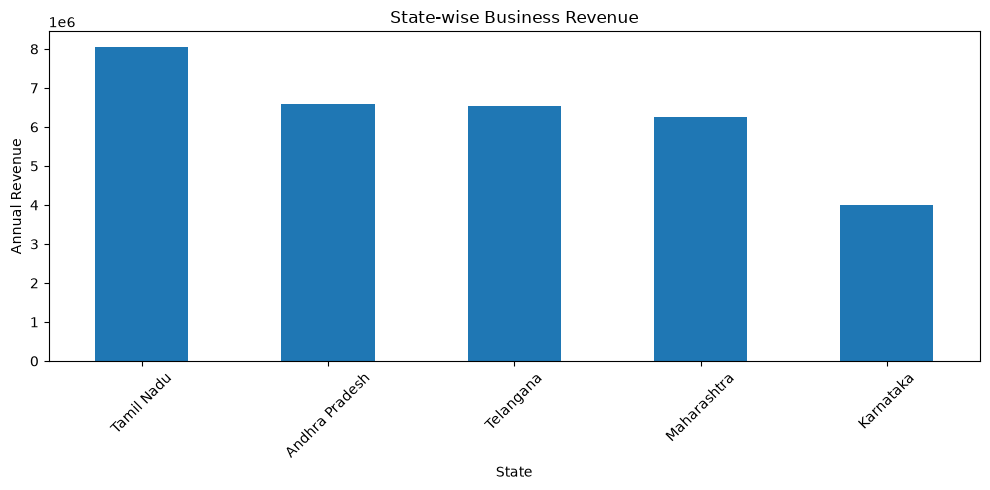

In [20]:
state_revenue.sort_values(ascending=False).plot(
    kind='bar',
    figsize=(10, 5),
    title='State-wise Business Revenue'
)

plt.xlabel('State')
plt.ylabel('Annual Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
city_count = df['city'].value_counts()

print("Business Count by City:")
print(city_count)

Business Count by City:
city
Tirupati     10
Hyderabad    10
Bengaluru    10
Chennai      10
Pune         10
Name: count, dtype: int64


In [22]:
top_cities = city_count.head(5)

print("Top 5 Cities:")
print(top_cities)

Top 5 Cities:
city
Tirupati     10
Hyderabad    10
Bengaluru    10
Chennai      10
Pune         10
Name: count, dtype: int64


In [23]:
city_revenue = df.groupby('city')['annual_revenue'].sum()

print("City-wise Revenue:")
print(city_revenue.sort_values(ascending=False).head(10))

City-wise Revenue:
city
Chennai      8050000
Tirupati     6600000
Hyderabad    6550000
Pune         6250000
Bengaluru    4000000
Name: annual_revenue, dtype: int64


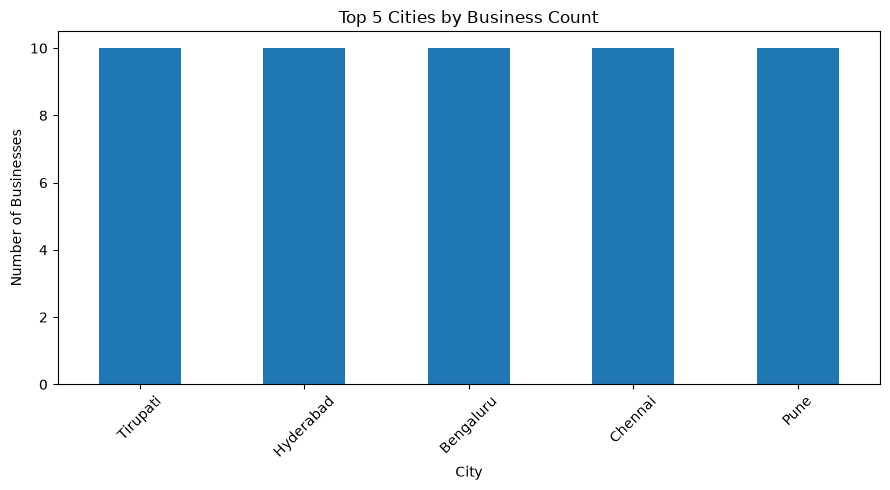

In [24]:
top_cities.plot(
    kind='bar',
    figsize=(9, 5),
    title='Top 5 Cities by Business Count'
)

plt.xlabel('City')
plt.ylabel('Number of Businesses')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
from pandasai import SmartDataframe
from pandasai.llm.local_llm import LocalLLM

model = LocalLLM(
    api_base="http://localhost:11434/v1",
    model="qwen2.5:1.5b"
)

print("PandasAI model connected successfully!")

PandasAI model connected successfully!


In [26]:
ai_df = df[
    ['business_name', 'state', 'city', 'age', 'annual_revenue']
].copy()

sdf = SmartDataframe(
    ai_df,
    config={"llm": model}
)

print("AI-powered dataset is ready!")

AI-powered dataset is ready!


In [28]:
from pandasai import SmartDataframe
from pandasai.llm.local_llm import LocalLLM

model = LocalLLM(
    api_base="http://localhost:11434/v1",
    model="qwen2.5:1.5b"
)

sdf = SmartDataframe(
    ai_df,
    config={"llm": model}
)

print("PandasAI connected successfully!")

PandasAI connected successfully!


In [29]:
response = sdf.chat(
    "Which state has the highest total annual revenue?"
)

print(response)

{'type': 'number', 'value': np.int64(8050000)}
8050000


In [31]:
import os

print("Current folder:", os.getcwd())

ai_df.to_csv("data.csv", index=False)

print("data.csv created successfully!")

Current folder: c:\Users\saite\cynaris-internship-saikrishna\week-5\W5D5
data.csv created successfully!


In [32]:
from pandasai import SmartDataframe
from pandasai.llm.local_llm import LocalLLM

model = LocalLLM(
    api_base="http://localhost:11434/v1",
    model="qwen2.5:3b"
)

sdf = SmartDataframe(
    ai_df,
    config={"llm": model}
)

print("PandasAI configured with Qwen 3B!")

PandasAI configured with Qwen 3B!


In [33]:
response = sdf.chat(
    "Calculate the sum of annual_revenue and return the numerical result."
)

print(response)

31450000


In [34]:
print(response)

31450000


In [35]:
print(sdf.chat("What is the average annual revenue?"))

629000.0


In [36]:
questions = [
    "What is the total annual revenue?",
    "What is the average annual revenue?",
    "Which state has the highest total revenue?",
    "Which city has the most businesses?",
    "Show the top 5 businesses by annual revenue.",
    "Which state has the highest number of businesses?",
    "What is the maximum annual revenue?",
    "What is the minimum annual revenue?"
]

for i, question in enumerate(questions, 1):
    print(f"\nQuestion {i}: {question}")

    try:
        answer = sdf.chat(question)
        print("Answer:", answer)

    except Exception as e:
        print("Error:", e)

    print("-" * 60)


Question 1: What is the total annual revenue?
Answer: 31450000
------------------------------------------------------------

Question 2: What is the average annual revenue?
Answer: 629000.0
------------------------------------------------------------

Question 3: Which state has the highest total revenue?
Answer: The state with the highest total revenue is Andhra Pradesh.
------------------------------------------------------------

Question 4: Which city has the most businesses?
Answer: The city with the most businesses is Bengaluru.
------------------------------------------------------------

Question 5: Show the top 5 businesses by annual revenue.
Answer:    business_name       state     city  age  annual_revenue  total_revenue
13    Green Mart  Tamil Nadu  Chennai   51          900000        8860000
3     Green Mart  Tamil Nadu  Chennai   51          900000        2570000
33    Green Mart  Tamil Nadu  Chennai   51          900000       21440000
43    Green Mart  Tamil Nadu  Chenn

In [37]:
top5 = (
    df.sort_values(
        by='annual_revenue',
        ascending=False
    )
    .drop_duplicates(subset='business_id')
    .head(5)
)

top5[['business_id', 'business_name',
      'state', 'city', 'annual_revenue']]

,business_id,business_name,state,city,annual_revenue
13,B014,Green Mart,Tamil Nadu,Chennai,900000
3,B004,Green Mart,Tamil Nadu,Chennai,900000
33,B034,Green Mart,Tamil Nadu,Chennai,900000
43,B044,Green Mart,Tamil Nadu,Chennai,900000
23,B024,Green Mart,Tamil Nadu,Chennai,900000


In [38]:
findings = {
    "Total Revenue": df['annual_revenue'].sum(),
    "Average Revenue": df['annual_revenue'].mean(),
    "Highest Revenue": df['annual_revenue'].max(),
    "Lowest Revenue": df['annual_revenue'].min(),
    "Total Businesses": df['business_id'].nunique(),
    "Highest Revenue State": df.groupby(
        'state'
    )['annual_revenue'].sum().idxmax()
}

for key, value in findings.items():
    print(f"{key}: {value}")

Total Revenue: 31450000
Average Revenue: 629000.0
Highest Revenue: 900000
Lowest Revenue: 380000
Total Businesses: 49
Highest Revenue State: Tamil Nadu


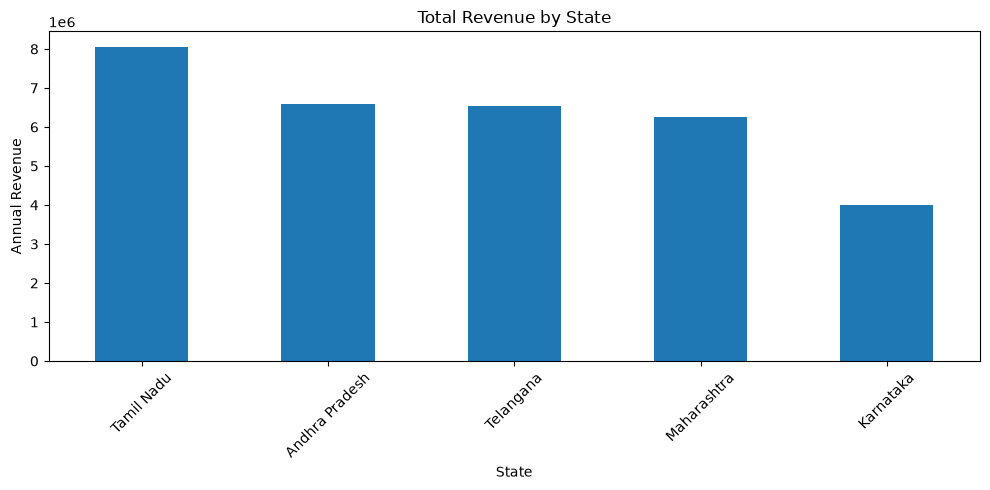

In [39]:
state_revenue = df.groupby('state')['annual_revenue'].sum()

plt.figure(figsize=(10, 5))
state_revenue.sort_values(ascending=False).plot(kind='bar')

plt.title('Total Revenue by State')
plt.xlabel('State')
plt.ylabel('Annual Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

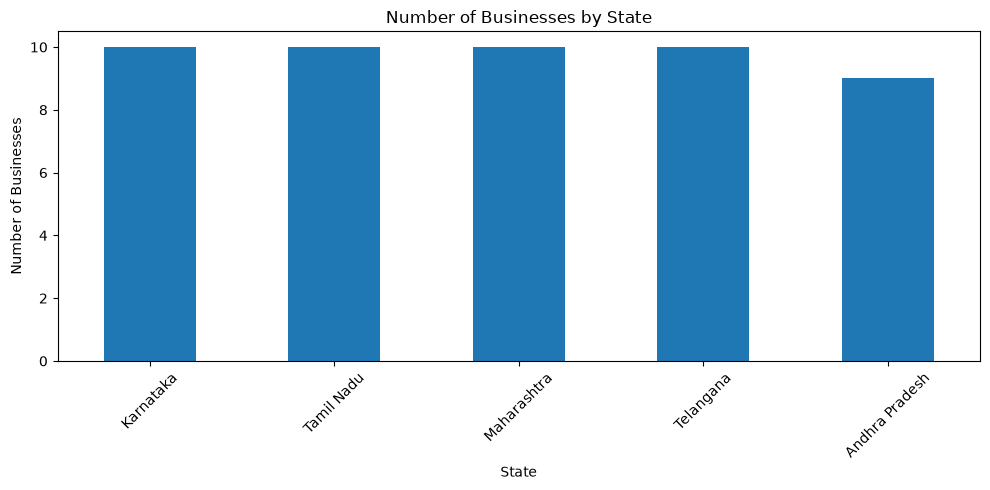

In [40]:
state_count = df.groupby('state')['business_id'].nunique()

plt.figure(figsize=(10, 5))
state_count.sort_values(ascending=False).plot(kind='bar')

plt.title('Number of Businesses by State')
plt.xlabel('State')
plt.ylabel('Number of Businesses')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

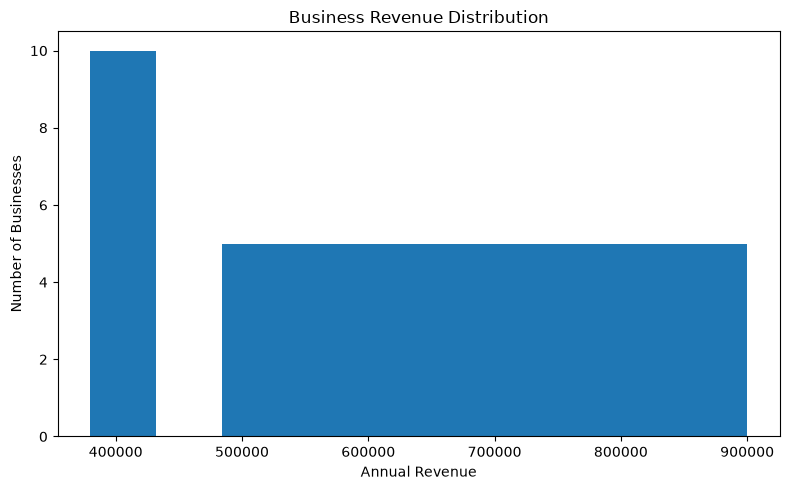

In [41]:
plt.figure(figsize=(8, 5))

plt.hist(df['annual_revenue'], bins=10)

plt.title('Business Revenue Distribution')
plt.xlabel('Annual Revenue')
plt.ylabel('Number of Businesses')

plt.tight_layout()
plt.show()

In [42]:
import os

os.makedirs('charts', exist_ok=True)

plt.figure(figsize=(10, 5))
state_revenue.sort_values(ascending=False).plot(kind='bar')
plt.title('Revenue by State')
plt.tight_layout()
plt.savefig('charts/revenue_by_state.png')
plt.close()

plt.figure(figsize=(10, 5))
state_count.sort_values(ascending=False).plot(kind='bar')
plt.title('Businesses by State')
plt.tight_layout()
plt.savefig('charts/businesses_by_state.png')
plt.close()

plt.figure(figsize=(8, 5))
plt.hist(df['annual_revenue'], bins=10)
plt.title('Revenue Distribution')
plt.tight_layout()
plt.savefig('charts/revenue_distribution.png')
plt.close()

print("All charts saved successfully!")

All charts saved successfully!


In [43]:
df.to_csv(
    'cleaned_indian_business_dataset.csv',
    index=False
)

print("Cleaned dataset saved!")

Cleaned dataset saved!


In [44]:
print("REVENUE BY STATE")
print(
    df.groupby('state')['annual_revenue']
    .sum()
    .sort_values(ascending=False)
)

print("\nBUSINESS COUNT BY CITY")
print(
    df.groupby('city')['business_id']
    .nunique()
    .sort_values(ascending=False)
)

print("\nTOP 5 UNIQUE BUSINESSES")
print(
    df.sort_values('annual_revenue', ascending=False)
    .drop_duplicates('business_id')
    [['business_id', 'business_name', 'annual_revenue']]
    .head(5)
)

REVENUE BY STATE
state
Tamil Nadu        8050000
Andhra Pradesh    6600000
Telangana         6550000
Maharashtra       6250000
Karnataka         4000000
Name: annual_revenue, dtype: int64

BUSINESS COUNT BY CITY
city
Bengaluru    10
Chennai      10
Hyderabad    10
Pune         10
Tirupati      9
Name: business_id, dtype: int64

TOP 5 UNIQUE BUSINESSES
   business_id business_name  annual_revenue
13        B014    Green Mart          900000
3         B004    Green Mart          900000
33        B034    Green Mart          900000
43        B044    Green Mart          900000
23        B024    Green Mart          900000
